# Kunci Lab 03: variabel dummy dan uji asumsi klasik



**Pengayaan pilihan:** evaluasi bantuan dengan DiD (25 sampai 35 menit). Waktu ini di luar durasi materi inti.

## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita memeriksa dummy dan asumsi model. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah pola antarfitur dan pola residual sebelum membaca hasil uji.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. Latihan: heteroskedastisitas (hetero_2.csv)



<!-- kamus_variabel:hetero_2.csv -->

### Kenali data: Pendapatan dan karakteristik pekerja

**Data:** `data/hetero_2.csv`. **Satu baris:** satu orang pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Pendapatan` | Pendapatan selama satu tahun. | Puluhan juta rupiah per tahun, sesuai uraian sumber | Y: target |
| `Pendidikan` | Lama pendidikan yang telah ditempuh. | Tahun | X: penjelas |
| `Pengalaman` | Lama pengalaman kerja. | Tahun | X: penjelas |
| `Usia` | Umur orang yang diamati. | Tahun | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

kerja = pd.read_csv(URL_DATA + "hetero_2.csv")

kerja.head()

,Pendapatan,Pendidikan,Pengalaman,Usia
0,85.67,12,5,28
1,151.02,16,10,35
2,102.43,14,7,31
3,185.33,18,15,40
4,91.11,12,6,29


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
sampel_model_kerja = kerja[["Pendapatan", "Pendidikan", "Pengalaman", "Usia"]].dropna()
X_model_kerja = sampel_model_kerja[["Pendidikan", "Pengalaman", "Usia"]]
y_model_kerja = sampel_model_kerja["Pendapatan"]

In [5]:
model_kerja = LinearRegression()
model_kerja.fit(X_model_kerja, y_model_kerja)

prediksi_model_kerja = pd.Series(
    model_kerja.predict(X_model_kerja), index=y_model_kerja.index
)
residu_model_kerja = y_model_kerja - prediksi_model_kerja

### Lihat hasil model: Produktivitas kerja (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

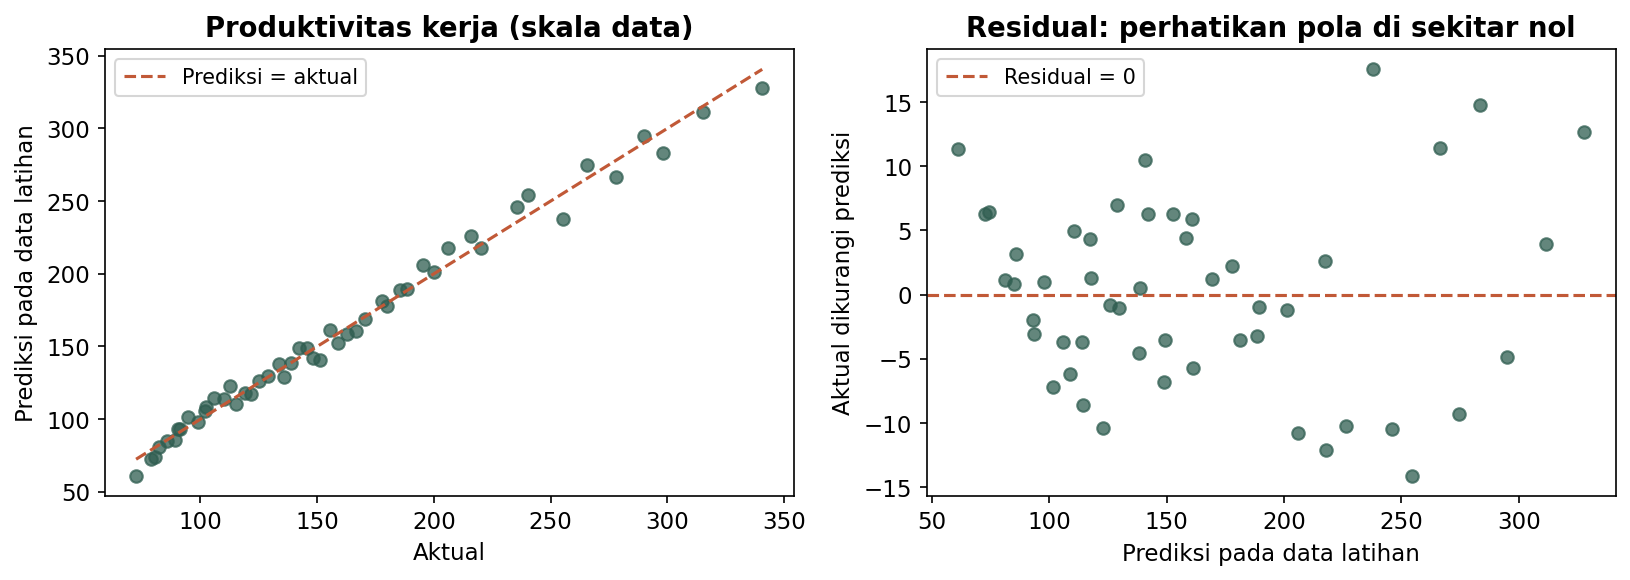

In [6]:
prediksi_visual = model_kerja.predict(X_model_kerja)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_kerja, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_kerja.min(), y_model_kerja.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Produktivitas kerja (skala data)")
axes[1].scatter(prediksi_visual, y_model_kerja - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [7]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_kerja = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

Xk = sm.add_constant(kerja[["Pendidikan", "Pengalaman", "Usia"]])
print("BP p   :", round(het_breuschpagan(residu_model_kerja, Xk)[1], 4))
print("White p:", round(het_white(residu_model_kerja, Xk)[1], 4))

# Pelengkap inferensi: koreksi standard error, dengan X dan y yang sama.
uji_model_robust = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(cov_type="HC3")
banding = pd.DataFrame(
    {
        "p_biasa": uji_model_kerja.pvalues,
        "p_robust": uji_model_robust.pvalues,
    }
)
print(banding.round(4))

BP p   : 0.0025
White p: 0.0638
            p_biasa  p_robust
Intercept    0.7391    0.7164
Pendidikan   0.0089    0.0286
Pengalaman   0.0000    0.0000
Usia         0.6495    0.6084


Kesimpulan: Breusch-Pagan menolak homoskedastis (p = 0,0025), White
tidak menolak pada 5% (p = 0,064). Karena ada bukti heteroskedastis,
laporkan versi robust. Perubahan yang terlihat: p-value pendidikan
naik dari 0,0089 ke 0,0286, tetap signifikan tapi lebih lemah.



## 2. Latihan: normalitas (latihan_normalitas_3.csv)



<!-- kamus_variabel:latihan_normalitas_3.csv -->

### Kenali data: Harga dan kondisi rumah

**Data:** `data/latihan_normalitas_3.csv`. **Satu baris:** satu rumah pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Harga` | Harga jual rumah pada data simulasi. | Sumber menyebut juta rupiah sekaligus simulasi dolar; skala ambigu | Y: target |
| `Luas_Bangunan` | Luas bangunan rumah. | Sumber menyebut m² sekaligus simulasi kaki persegi; skala ambigu | X: penjelas |
| `Jumlah_Kamar` | Jumlah kamar tidur. | Kamar | X: penjelas |
| `Usia_Rumah` | Lama sejak rumah dibangun. | Tahun | X: penjelas |

Sumber mencampurkan keterangan satuan untuk harga dan luas. Gunakan angka ini untuk latihan statistik; konfirmasi satuan sebelum memberi interpretasi nominal atau mengonversi luas.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [8]:
from statsmodels.stats.stattools import jarque_bera
import seaborn as sns

nrumah = pd.read_csv(URL_DATA + "latihan_normalitas_3.csv")

nrumah.head()

,Harga,Luas_Bangunan,Jumlah_Kamar,Usia_Rumah
0,350,1800,3,15
1,320,1700,3,20
2,380,1900,4,10
3,410,2100,4,5
4,290,1600,3,25


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [9]:
sampel_model_n = nrumah[
    ["Harga", "Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]
].dropna()
X_model_n = sampel_model_n[["Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]]
y_model_n = sampel_model_n["Harga"]

Jarque-Bera = 3.1868, p = 0.2032


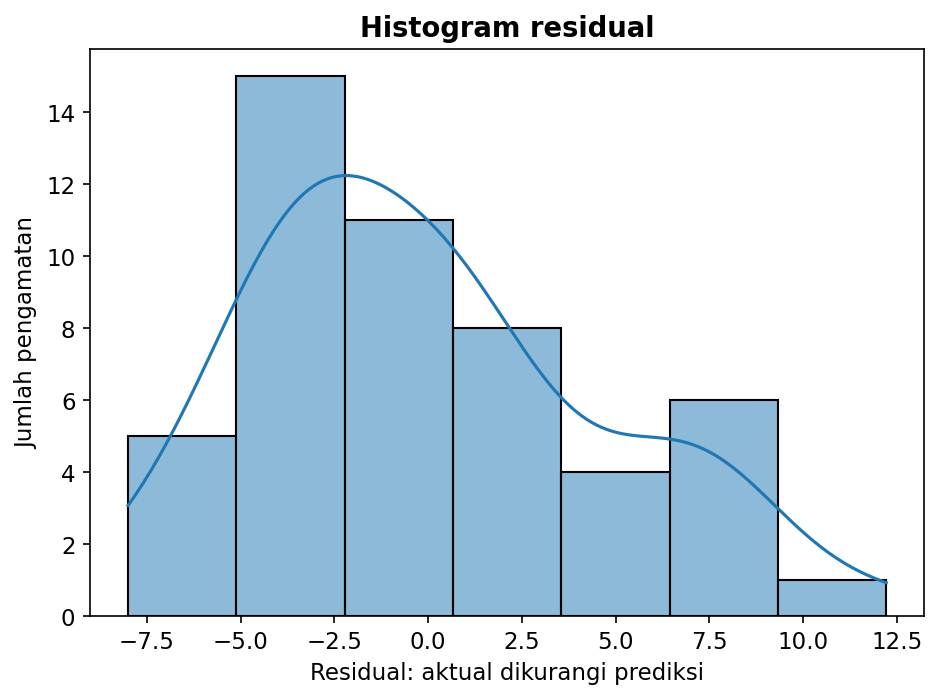

In [10]:
model_n = LinearRegression()
model_n.fit(X_model_n, y_model_n)

prediksi_model_n = pd.Series(model_n.predict(X_model_n), index=y_model_n.index)
residu_model_n = y_model_n - prediksi_model_n

jb, p_jb, skew, kurt = jarque_bera(residu_model_n)
print(f"Jarque-Bera = {jb:.4f}, p = {p_jb:.4f}")

sns.histplot(residu_model_n, kde=True)
plt.title("Histogram residual")
plt.xlabel("Residual: aktual dikurangi prediksi")
plt.ylabel("Jumlah pengamatan")
plt.tight_layout()
plt.show()

**Baca grafik sebelum lanjut:** histogram menunjukkan banyaknya residual pada tiap rentang. Perhatikan kemencengan dan ekor distribusi, lalu cocokkan dengan hasil uji normalitas. Tinggi batang menyatakan jumlah pengamatan, bukan nilai prediksi.

Kesimpulan: p = 0,2032 di atas 0,05, jadi residual tidak menyimpang
jauh dari normal menurut uji ini; gagal menolak bukan membuktikan normalitas.



## 3. Latihan: kasus tanpa pelanggaran (hetero_1.csv)



<!-- kamus_variabel:hetero_1.csv -->

### Kenali data: Iklan, tenaga penjualan, dan diskon

**Data:** `data/hetero_1.csv`. **Satu baris:** satu pengamatan penjualan perusahaan dalam contoh.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Penjualan` | Banyaknya produk terjual. | Ribuan unit | Y: target |
| `Iklan` | Pengeluaran untuk iklan. | Juta rupiah | X: penjelas |
| `Salesperson` | Jumlah tenaga penjualan yang bekerja. | Orang | X: penjelas |
| `Diskon` | Rata-rata potongan harga yang diberikan. | Persen; 5,2 berarti 5,2% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [11]:
jual = pd.read_csv(URL_DATA + "hetero_1.csv")

jual.head()

,Penjualan,Iklan,Salesperson,Diskon
0,231.83,10.5,8,5.2
1,272.94,12.2,9,6.1
2,251.35,11.8,7,5.5
3,333.31,15.1,10,7.3
4,311.66,14.5,11,6.8


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [12]:
sampel_model_jual = jual[["Penjualan", "Iklan", "Salesperson", "Diskon"]].dropna()
X_model_jual = sampel_model_jual[["Iklan", "Salesperson", "Diskon"]]
y_model_jual = sampel_model_jual["Penjualan"]

In [13]:
model_jual = LinearRegression()
model_jual.fit(X_model_jual, y_model_jual)

prediksi_model_jual = pd.Series(
    model_jual.predict(X_model_jual), index=y_model_jual.index
)
residu_model_jual = y_model_jual - prediksi_model_jual
Xj = sm.add_constant(jual[["Iklan", "Salesperson", "Diskon"]])
print("BP p   :", round(het_breuschpagan(residu_model_jual, Xj)[1], 4))
print("White p:", round(het_white(residu_model_jual, Xj)[1], 4))

BP p   : 0.9969
White p: 0.5424


### Lihat hasil model: Penjualan (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

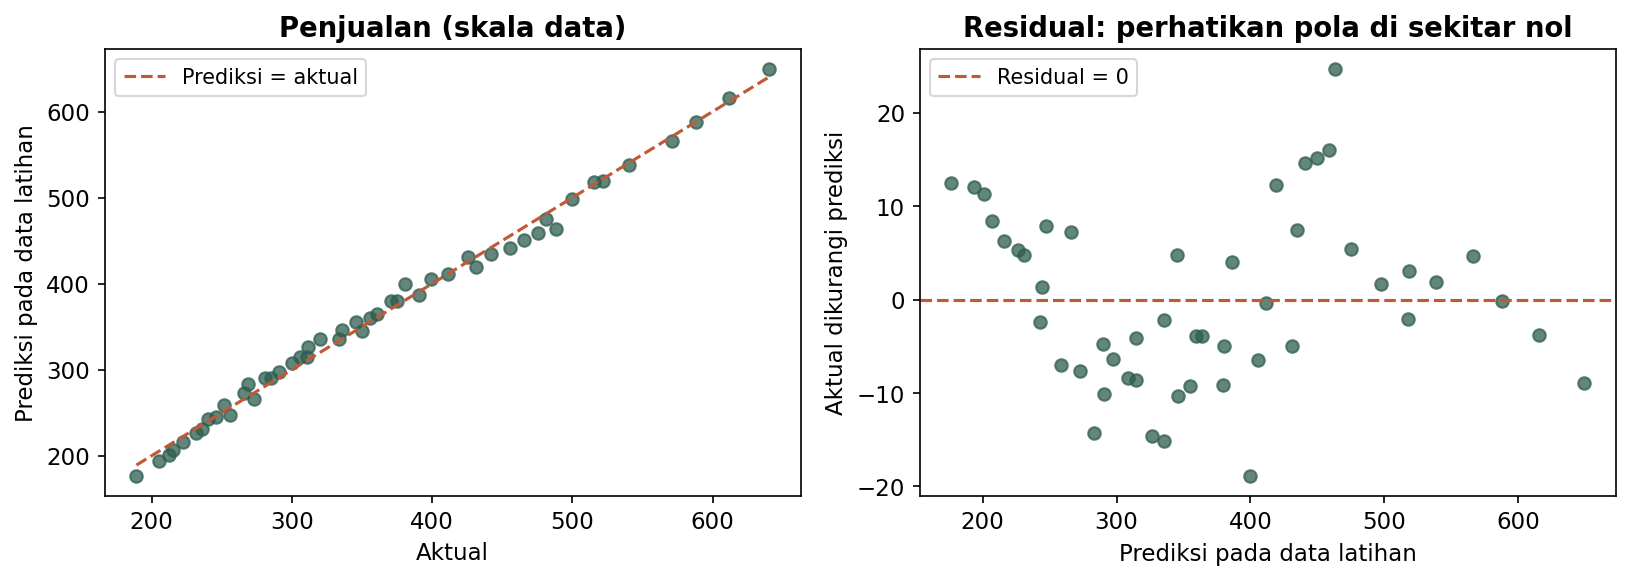

In [14]:
prediksi_visual = model_jual.predict(X_model_jual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_jual, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_jual.min(), y_model_jual.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (skala data)")
axes[1].scatter(prediksi_visual, y_model_jual - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

Kesimpulan: kedua uji tidak menolak homoskedastis (p = 0,997 dan 0,542).
Dugaan "variabilitas penjualan membesar saat iklan tinggi" tidak
didukung data ini. Yang benar: laporkan apa adanya, jangan paksakan
narasi. Ini juga contoh bahwa hipotesis bisa ditolak data.


## Pengayaan: apakah bantuan menaikkan pendapatan? (25 sampai 35 menit)

Dummy membedakan kelompok, tetapi perbedaannya belum otomatis menunjukkan
akibat program. Misalnya, penerima bantuan mungkin sejak awal lebih miskin.
Kita perlu memikirkan apa yang akan terjadi pada penerima jika bantuan tidak ada.

**Pertanyaan:** berapa tambahan pendapatan yang dapat dikaitkan dengan program,
setelah memperhitungkan perubahan pada kelompok pembanding?
Gunakan *difference-in-differences* (DiD), yaitu selisih dari dua perubahan.
Angka berikut **simulasi untuk latihan**, bukan hasil evaluasi PKH atau program nyata.
Program ilustrasi mulai pada 2023; dua tahun sebelumnya membantu melihat pola awal.

<!-- kamus_variabel:contoh_did -->

### Kenali data: Simulasi evaluasi bantuan dan pendapatan

**Data:** tabel contoh yang dibuat langsung di kode. **Satu baris:** satu kelompok pada satu tahun; delapan baris agregat, bukan delapan rumah tangga.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `tahun` | Tahun pengamatan kelompok. | 2021 sampai 2024 | Penanda waktu |
| `peserta` | Penanda kelompok yang akan menerima program mulai 2023. | 1 = peserta; 0 = pembanding | X: dummy kelompok |
| `pendapatan` | Rata-rata pendapatan rumah tangga pada kelompok dan tahun tersebut. | Juta rupiah per bulan | Y: hasil yang dibandingkan |

Semua nilai adalah simulasi. Program mulai 2023. Setiap baris memiliki bobot sama untuk latihan; ini bukan hasil evaluasi PKH dan bukan dasar pengujian signifikansi statistik.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `sesudah` | Penanda periode setelah program mulai. | 1 = tahun 2023 atau 2024; 0 = tahun 2021 atau 2022 |
| `interaksi` | Perkalian peserta dan sesudah; bernilai satu pada peserta setelah program. | Dummy 0 atau 1 |

Sumber: Angka ilustrasi buatan untuk pengantar DiD dalam notebook Sesi 03.


In [15]:
from IPython.display import display

bantuan_did = pd.DataFrame({
    "tahun": [2021, 2022, 2023, 2024, 2021, 2022, 2023, 2024],
    "peserta": [0, 0, 0, 0, 1, 1, 1, 1],
    "pendapatan": [2.0, 2.2, 2.4, 2.6, 1.5, 1.7, 2.2, 2.4],
})
bantuan_did["sesudah"] = (bantuan_did["tahun"] >= 2023).astype(int)
bantuan_did["interaksi"] = bantuan_did["peserta"] * bantuan_did["sesudah"]
bantuan_did

,tahun,peserta,pendapatan,sesudah,interaksi
0,2021,0,2.0,0,0
1,2022,0,2.2,0,0
2,2023,0,2.4,1,0
3,2024,0,2.6,1,0
4,2021,1,1.5,0,0
5,2022,1,1.7,0,0
6,2023,1,2.2,1,1
7,2024,1,2.4,1,1


### 1. Amati perubahan kedua kelompok

`pivot` menata rata-rata pendapatan menjadi dua kolom kelompok dan satu baris
untuk setiap tahun. Garis putus-putus menggambarkan pendapatan peserta jika
selisih awal terhadap pembanding tetap sama sesudah program.

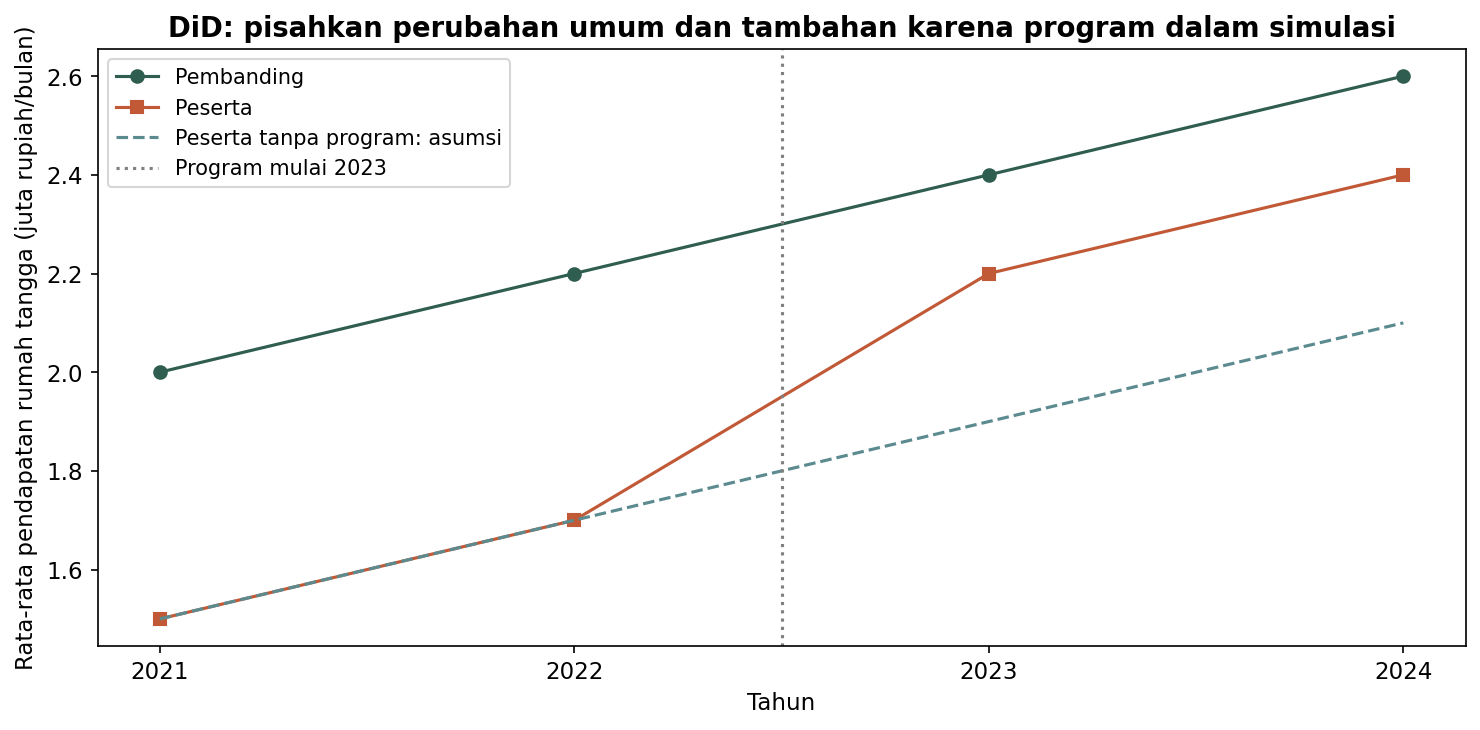

In [16]:
rata_tahunan_did = bantuan_did.pivot(index="tahun", columns="peserta", values="pendapatan")
selisih_awal_did = rata_tahunan_did.loc[2022, 1] - rata_tahunan_did.loc[2022, 0]
tanpa_program_did = rata_tahunan_did[0] + selisih_awal_did

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rata_tahunan_did.index, rata_tahunan_did[0], "o-", color="#2F5D50", label="Pembanding")
ax.plot(rata_tahunan_did.index, rata_tahunan_did[1], "s-", color="#C15937", label="Peserta")
ax.plot(tanpa_program_did.index, tanpa_program_did, "--", color="#5B8A8F", label="Peserta tanpa program: asumsi")
ax.axvline(2022.5, color="gray", linestyle=":", label="Program mulai 2023")
ax.set_xticks([2021, 2022, 2023, 2024])
ax.set_xlabel("Tahun")
ax.set_ylabel("Rata-rata pendapatan rumah tangga (juta rupiah/bulan)")
ax.set_title("DiD: pisahkan perubahan umum dan tambahan karena program dalam simulasi")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** kedua kelompok sudah berbeda sebelum program, tetapi kenaikan
2021 ke 2022 sama, yaitu 0,2 juta rupiah. Setelah 2023, garis peserta berada
0,3 juta di atas garis putus-putus. Garis putus-putus adalah keadaan pembanding
yang diasumsikan; kita tidak mengamatinya secara langsung setelah bantuan dimulai.

### 2. Hitung dari empat rata-rata

`groupby` menghitung rata-rata per kelompok dan periode. `unstack` memindahkan
periode menjadi kolom: 0 sebelum program, 1 sesudah program. Setiap rata-rata
merangkum dua tahun dengan bobot sama pada simulasi ini.

In [17]:
tabel_did = bantuan_did.groupby(["peserta", "sesudah"])["pendapatan"].mean().unstack("sesudah")
perubahan_did = tabel_did[1] - tabel_did[0]
dampak_did = perubahan_did.loc[1] - perubahan_did.loc[0]

print("Rata-rata sebelum (0) dan sesudah (1):")
display(tabel_did.round(2))
print("Perubahan peserta:", round(perubahan_did.loc[1], 2), "juta rupiah/bulan")
print("Perubahan pembanding:", round(perubahan_did.loc[0], 2), "juta rupiah/bulan")
print("DiD:", round(dampak_did, 2), "juta rupiah/bulan")

Rata-rata sebelum (0) dan sesudah (1):


sesudah,0,1
peserta,,
0,2.1,2.5
1,1.6,2.3


Perubahan peserta: 0.7 juta rupiah/bulan
Perubahan pembanding: 0.4 juta rupiah/bulan
DiD: 0.3 juta rupiah/bulan


Pendapatan peserta naik **0,7 juta**, sedangkan pembanding naik **0,4 juta**.
Selisihnya **0,3 juta rupiah atau Rp300.000 per bulan**. Membaca kenaikan 0,7 juta
sebagai akibat bantuan akan mencampurkan perubahan umum dan tambahan program.

### 3. Cocokkan dengan regresi yang sudah kita kenal

`interaksi` bernilai 1 hanya pada peserta setelah program. Dengan intersep,
dummy peserta, dan dummy sesudah, koefisien interaksi sama dengan perhitungan DiD.

In [18]:
X_model_did = bantuan_did[["peserta", "sesudah", "interaksi"]]
y_model_did = bantuan_did["pendapatan"]
model_did = LinearRegression()
model_did.fit(X_model_did, y_model_did)
koefisien_model_did = pd.Series(model_did.coef_, index=X_model_did.columns)
print(koefisien_model_did.round(2))
print("Koefisien interaksi:", round(koefisien_model_did.loc["interaksi"], 2))

peserta     -0.5
sesudah      0.4
interaksi    0.3
dtype: float64
Koefisien interaksi: 0.3


### 4. Syarat membaca DiD sebagai dampak

- Tanpa program, perubahan kedua kelompok diasumsikan mengikuti tren yang sama.
- Tidak ada program atau guncangan lain yang hanya mengenai satu kelompok pada saat yang sama.
- Komposisi kelompok tetap sebanding, tidak ada antisipasi sebelum program, dan tidak ada pengaruh program ke pembanding.

Kesamaan satu perubahan sebelum program hanya petunjuk awal. Data nyata memerlukan
lebih banyak periode awal, alasan pemilihan pembanding, dan pemeriksaan kepekaan.
Delapan baris agregat ini cukup untuk hitungan pengantar; **jangan gunakan untuk
menyimpulkan signifikansi statistik**. Penelitian dengan banyak unit perlu menghitung
ketidakpastian sesuai rancangan, misalnya standard error yang dikelompokkan menurut unit program.

**Hubungan dengan Indonesia.** Evaluasi PKH oleh Cahyadi dan rekan-rekan (2020)
memanfaatkan penugasan program secara acak, bukan DiD sederhana seperti latihan ini.
Studi SD Inpres oleh Duflo (2001) memanfaatkan variasi pembangunan sekolah antarwilayah
dan angkatan usia. Keduanya menunjukkan bahwa rancangan pembanding menentukan arti koefisien.

Rujukan: [DiD, World Bank](https://dimewiki.worldbank.org/Difference-in-Differences),
[PKH, Cahyadi dkk.](https://economics.mit.edu/sites/default/files/publications/pol.20190245.pdf),
[SD Inpres, Duflo](https://pubs.aeaweb.org/doi/10.1257/aer.91.4.795).

### Coba sendiri: periksa satu perubahan sebelum dan sesudah program

Hitung DiD hanya untuk perubahan 2022 ke 2023 dari `rata_tahunan_did`.
Apakah hasilnya sama dengan 0,3 juta? Jelaskan mengapa program lain yang
hanya mengenai peserta pada 2023 akan mengganggu tafsir sebab-akibat.

In [19]:
perubahan_peserta_did = rata_tahunan_did.loc[2023, 1] - rata_tahunan_did.loc[2022, 1]
perubahan_pembanding_did = rata_tahunan_did.loc[2023, 0] - rata_tahunan_did.loc[2022, 0]
did_satu_tahun = perubahan_peserta_did - perubahan_pembanding_did
print("DiD 2022 ke 2023:", round(did_satu_tahun, 2), "juta rupiah/bulan")

DiD 2022 ke 2023: 0.3 juta rupiah/bulan


**Pembahasan:** Peserta naik 0,5 juta, pembanding naik 0,2 juta, sehingga DiD tetap 0,3 juta. Jika hanya peserta mendapat program lain pada saat yang sama, selisih itu mencampurkan akibat dua program; DiD ini tidak dapat memisahkannya.

## Selanjutnya

Kembali ke [Lab 03](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/03_dummy_asumsi_klasik.ipynb) dan cocokkan langkah serta interpretasinya. Gunakan [panduan pengajar](https://github.com/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/pengajar/README.md#pembahasan-latihan) untuk pembahasan bersama.